In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

"This cell sets up our dataframe and gives us a full list of columns"

# Our pitchfork data
pitchfork = "/content/drive/MyDrive/Colab Notebooks/Datasets/pitchfork.csv"
review_df = df=pd.read_csv(pitchfork)

# Default look for every plot in the notebook.
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

review_df.columns

Index(['artist', 'album', 'reviewauthor', 'score', 'releaseyear', 'reviewdate', 'recordlabel', 'genre', 'danceability',
       'energy', 'key', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'],
      dtype='object')

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

"This cell excludes columns which are not of interest and defines score as our main variable to predict"

# 1. Define the target and features
target = "score"

features = [
    "releaseyear",
    "danceability",
    "energy",
    "key",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

# 2. Separate the score from the predictor features
X = review_df[features]
y = review_df[target]

In [10]:
"This cell fills empty values (should there be any) with median and standardizes value scales"

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 3. Impute missing values, encode categories, and standardize
preprocessor = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

# 4. Transform the feature matrix
X_processed = preprocessor.fit_transform(X)

# Retrieve the names of the transformed features
feature_names = preprocessor.get_feature_names_out()
print("Feature names:", feature_names)

Feature names: ['releaseyear' 'danceability' 'energy' 'key' 'loudness' 'speechiness'
 'acousticness' 'instrumentalness' 'liveness' 'valence' 'tempo']


In [12]:
"This cell gives size metrics for reference"

print("Number of reviews:", X_processed.shape[0])
print("Number of features:", X_processed.shape[1])
print(
    "Approximate matrix size in memory:",
    round(X_processed.nbytes / (1024**2), 2),
    "MB"
)

Number of reviews: 18403
Number of features: 11
Approximate matrix size in memory: 1.54 MB


In [14]:
"This cells fits and runs the PCA"

# 5. Fit PCA
pca = PCA()
X_pca = pca.fit_transform(X_processed)

pca_df = pd.DataFrame(
    X_pca,
    columns=[f"PC{i+1}" for i in range(X_pca.shape[1])],
    index=review_df.index
)

pca_df["score"] = y

# 6. Explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

variance_df = pd.DataFrame({
    "Principal Component": pca_df.columns[:-1],
    "Explained Variance Ratio": explained_variance,
    "Cumulative Explained Variance": cumulative_variance
})

print("\nExplained variance:")
print(variance_df.round(4))


Explained variance:
   Principal Component  Explained Variance Ratio  Cumulative Explained Variance
0                  PC1                    0.2940                         0.2940
1                  PC2                    0.1429                         0.4368
2                  PC3                    0.1109                         0.5477
3                  PC4                    0.0938                         0.6415
4                  PC5                    0.0920                         0.7335
5                  PC6                    0.0774                         0.8109
6                  PC7                    0.0659                         0.8768
7                  PC8                    0.0535                         0.9303
8                  PC9                    0.0327                         0.9629
9                 PC10                    0.0271                         0.9901
10                PC11                    0.0099                         1.0000


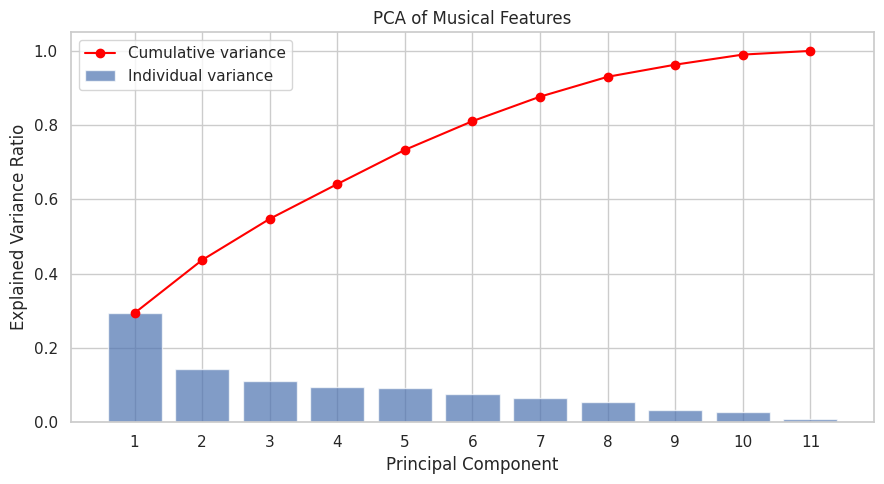


Feature loadings for PC1 and PC2:
                    PC1    PC2
releaseyear       0.013 -0.080
danceability      0.238  0.559
energy            0.476 -0.292
key               0.056  0.018
loudness          0.467 -0.179
speechiness       0.182  0.377
acousticness     -0.417  0.306
instrumentalness -0.271 -0.328
liveness          0.173 -0.070
valence           0.350  0.387
tempo             0.250 -0.256


In [18]:
"This cell plots the explained varance above"

# 7. Plot explained variance
plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance,
    alpha=0.7,
    label="Individual variance"
)

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o",
    color="red",
    label="Cumulative variance"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA of Musical Features")
plt.xticks(range(1, len(explained_variance) + 1))
plt.legend()
plt.tight_layout()
plt.show()

# 8. Inspect feature loadings
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=[f"PC{i+1}" for i in range(len(features))]
)

print("\nFeature loadings for PC1 and PC2:")
print(loadings[["PC1", "PC2"]].round(3))

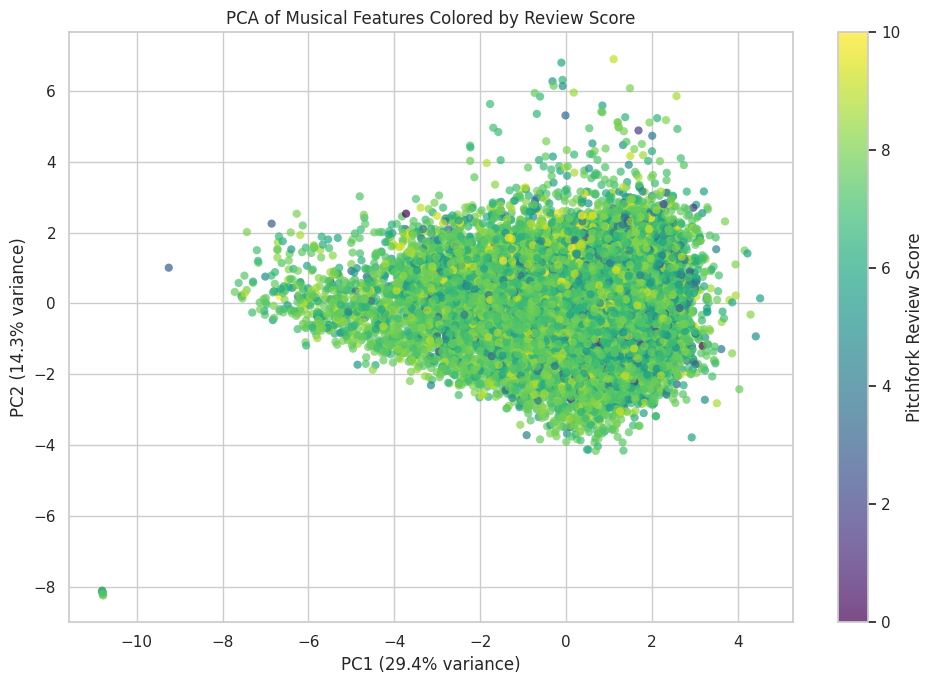

In [19]:
"This cell visualizes albums by reviw score using its first two PCs"

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=pca_df["score"],
    cmap="viridis",
    alpha=0.7,
    s=35,
    edgecolors="none"
)

plt.colorbar(scatter, label="Pitchfork Review Score")

plt.xlabel(
    f"PC1 ({explained_variance[0]:.1%} variance)"
)
plt.ylabel(
    f"PC2 ({explained_variance[1]:.1%} variance)"
)

plt.title("PCA of Musical Features Colored by Review Score")
plt.tight_layout()
plt.show()


Largest absolute loadings for PC1:
energy              0.476
loudness            0.467
acousticness       -0.417
valence             0.350
instrumentalness   -0.271
tempo               0.250
danceability        0.238
speechiness         0.182
liveness            0.173
key                 0.056
releaseyear         0.013
Name: PC1, dtype: float64

Largest absolute loadings for PC2:
danceability        0.559
valence             0.387
speechiness         0.377
instrumentalness   -0.328
acousticness        0.306
energy             -0.292
tempo              -0.256
loudness           -0.179
releaseyear        -0.080
liveness           -0.070
key                 0.018
Name: PC2, dtype: float64


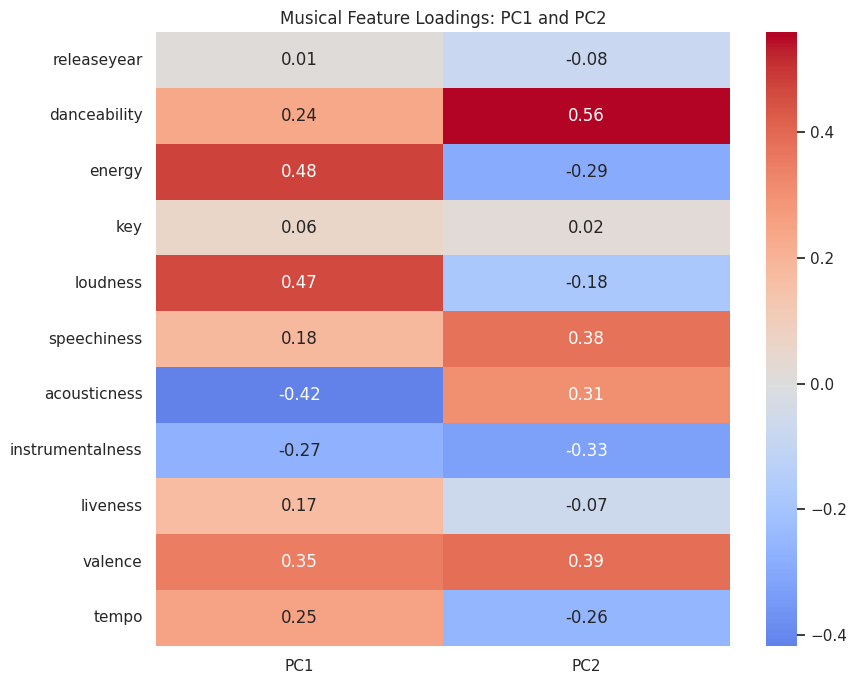

In [22]:
"This cells reiterates the features"

"""
Large absolute loadings indicate features that contribute strongly to a component.
Features with loadings of the same sign tend to contribute in the same direction along that component.
Features with opposite signs contribute in opposing directions.
A component might capture a contrast between energetic, loud music and quieter, more acoustic music, for example, depending on your actual results.
Remember that the sign of a component is arbitrary, so interpret the relative signs and magnitudes rather than whether a loading is positive or negative in isolation.
"""

# Create loadings DataFrame with original feature names
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=[f"PC{i+1}" for i in range(len(features))]
)

# Print the strongest contributors to PC1 and PC2
for pc in ["PC1", "PC2"]:
    print(f"\nLargest absolute loadings for {pc}:")

    print(
        loadings[pc]
        .sort_values(key=abs, ascending=False)
        .head(11)
        .round(3)
    )

# Plot feature loadings for the first two components
plt.figure(figsize=(9, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Musical Feature Loadings: PC1 and PC2")
plt.tight_layout()
plt.show()

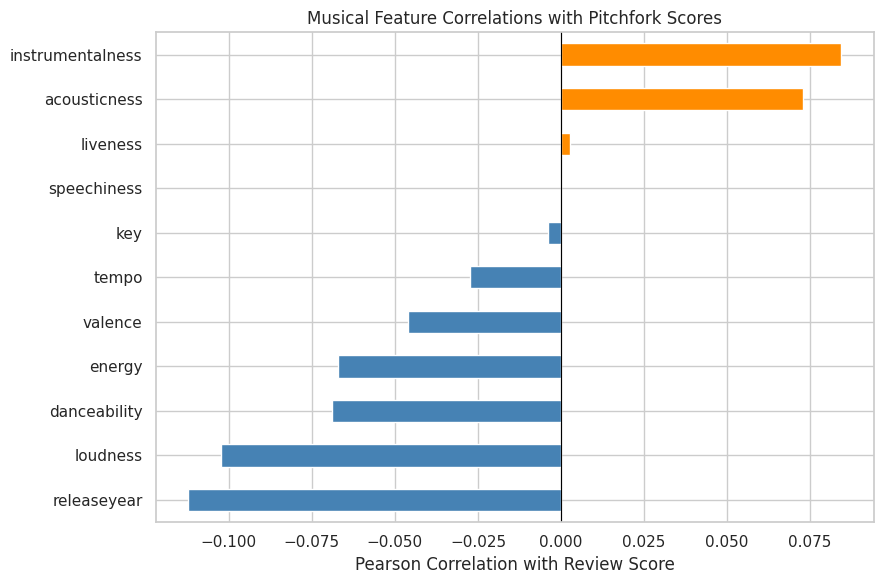


Feature correlations with review score:
releaseyear        -0.112
loudness           -0.102
danceability       -0.069
energy             -0.067
valence            -0.046
tempo              -0.027
key                -0.004
speechiness        -0.000
liveness            0.003
acousticness        0.073
instrumentalness    0.084
Name: score, dtype: float64


In [23]:
"This cells examins features against review score"

"""
PCA is unsupervised, so it doesn't directly identify which features predict score.
This step calculates Pearson correlations between the original numerical features and the review score.
"""

# Combine original numerical features with review score
numeric_df = df.loc[
    df["score"].notna(),
    features + ["score"]
].copy()

# Calculate correlations with score
score_correlations = (
    numeric_df.corr(numeric_only=True)["score"]
    .drop("score")
    .sort_values()
)

# Plot correlations
plt.figure(figsize=(9, 6))

colors = [
    "steelblue" if value < 0 else "darkorange"
    for value in score_correlations
]

score_correlations.plot(
    kind="barh",
    color=colors
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Pearson Correlation with Review Score")
plt.title("Musical Feature Correlations with Pitchfork Scores")
plt.tight_layout()
plt.show()

print("\nFeature correlations with review score:")
print(score_correlations.round(3))